# Heart Disease Predictor

## EDA

In [1]:
import pandas as pd

data = pd.read_csv('heart_disease.csv')
data

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,25.0,Female,136.0,243.0,Medium,Yes,No,No,18.788791,Yes,...,Yes,Medium,High,6.834954,Medium,343.0,133.0,3.588814,19.132004,Yes
9996,38.0,Male,172.0,154.0,Medium,No,No,No,31.856801,Yes,...,Yes,NaN,High,8.247784,Low,377.0,83.0,2.658267,9.715709,Yes
9997,73.0,Male,152.0,201.0,High,Yes,No,Yes,26.899911,No,...,Yes,NaN,Low,4.436762,Low,248.0,88.0,4.408867,9.492429,Yes
9998,23.0,Male,142.0,299.0,Low,Yes,No,Yes,34.964026,Yes,...,Yes,Medium,High,8.526329,Medium,113.0,153.0,7.215634,11.873486,Yes


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   str    
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   str    
 5   Smoking               9975 non-null   str    
 6   Family Heart Disease  9979 non-null   str    
 7   Diabetes              9970 non-null   str    
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   str    
 10  Low HDL Cholesterol   9975 non-null   str    
 11  High LDL Cholesterol  9974 non-null   str    
 12  Alcohol Consumption   7414 non-null   str    
 13  Stress Level          9978 non-null   str    
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption     9970 non-

In [3]:
data.isna().sum() / len(data) * 100

Age                      0.29
Gender                   0.19
Blood Pressure           0.19
Cholesterol Level        0.30
Exercise Habits          0.25
Smoking                  0.25
Family Heart Disease     0.21
Diabetes                 0.30
BMI                      0.22
High Blood Pressure      0.26
Low HDL Cholesterol      0.25
High LDL Cholesterol     0.26
Alcohol Consumption     25.86
Stress Level             0.22
Sleep Hours              0.25
Sugar Consumption        0.30
Triglyceride Level       0.26
Fasting Blood Sugar      0.22
CRP Level                0.26
Homocysteine Level       0.20
Heart Disease Status     0.00
dtype: float64

In [4]:
data.describe()

,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level
count,9971.000000,9981.000000,9970.000000,9978.000000,9975.000000,9974.000000,9978.000000,9974.000000,9980.000000
mean,49.296259,149.757740,225.425577,29.077269,6.991329,250.734409,120.142213,7.472201,12.456271
std,18.193970,17.572969,43.575809,6.307098,1.753195,87.067226,23.584011,4.340248,4.323426
min,18.000000,120.000000,150.000000,18.002837,4.000605,100.000000,80.000000,0.003647,5.000236
25%,34.000000,134.000000,187.000000,23.658075,5.449866,176.000000,99.000000,3.674126,8.723334
50%,49.000000,150.000000,226.000000,29.079492,7.003252,250.000000,120.000000,7.472164,12.409395
75%,65.000000,165.000000,263.000000,34.520015,8.531577,326.000000,141.000000,11.255592,16.140564
max,80.000000,180.000000,300.000000,39.996954,9.999952,400.000000,160.000000,14.997087,19.999037


In [5]:
data.duplicated().sum()

np.int64(0)

## Binary Columns

In [6]:
data

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,25.0,Female,136.0,243.0,Medium,Yes,No,No,18.788791,Yes,...,Yes,Medium,High,6.834954,Medium,343.0,133.0,3.588814,19.132004,Yes
9996,38.0,Male,172.0,154.0,Medium,No,No,No,31.856801,Yes,...,Yes,NaN,High,8.247784,Low,377.0,83.0,2.658267,9.715709,Yes
9997,73.0,Male,152.0,201.0,High,Yes,No,Yes,26.899911,No,...,Yes,NaN,Low,4.436762,Low,248.0,88.0,4.408867,9.492429,Yes
9998,23.0,Male,142.0,299.0,Low,Yes,No,Yes,34.964026,Yes,...,Yes,Medium,High,8.526329,Medium,113.0,153.0,7.215634,11.873486,Yes


In [7]:
binary_columns = data[ ['Gender', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'High LDL Cholesterol', 'Heart Disease Status'] ]

binary_columns.fillna('No', inplace=True)
binary_columns.isna().sum()

Gender                  0
Smoking                 0
Family Heart Disease    0
Diabetes                0
High Blood Pressure     0
High LDL Cholesterol    0
Heart Disease Status    0
dtype: int64

In [8]:
binary_columns = binary_columns.replace({
    'Yes': 1,
    'No': 0,
    'Male': 1,
    'Female': 0
})
binary_columns

,Gender,Smoking,Family Heart Disease,Diabetes,High Blood Pressure,High LDL Cholesterol,Heart Disease Status
0,1,1,1,0,1,0,0
1,0,0,1,1,0,0,0
2,1,0,0,0,0,1,0
3,0,1,1,0,1,1,0
4,1,1,1,1,1,0,0
...,...,...,...,...,...,...,...
9995,0,1,0,0,1,1,1
9996,1,0,0,0,1,1,1
9997,1,1,0,1,0,1,1
9998,1,1,0,1,1,1,1


In [9]:
data[ ['Gender', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'High LDL Cholesterol', 'Heart Disease Status'] ] = binary_columns
data

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,1,153.0,155.0,High,1,1,0,24.991591,1,...,0,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,0
1,69.0,0,146.0,286.0,High,0,1,1,25.221799,0,...,0,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,0
2,46.0,1,126.0,216.0,Low,0,0,0,29.855447,0,...,1,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,0
3,32.0,0,122.0,293.0,High,1,1,0,24.130477,1,...,1,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,0
4,60.0,1,166.0,242.0,Low,1,1,1,20.486289,1,...,0,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,25.0,0,136.0,243.0,Medium,1,0,0,18.788791,1,...,1,Medium,High,6.834954,Medium,343.0,133.0,3.588814,19.132004,1
9996,38.0,1,172.0,154.0,Medium,0,0,0,31.856801,1,...,1,NaN,High,8.247784,Low,377.0,83.0,2.658267,9.715709,1
9997,73.0,1,152.0,201.0,High,1,0,1,26.899911,0,...,1,NaN,Low,4.436762,Low,248.0,88.0,4.408867,9.492429,1
9998,23.0,1,142.0,299.0,Low,1,0,1,34.964026,1,...,1,Medium,High,8.526329,Medium,113.0,153.0,7.215634,11.873486,1


## Ordinal Features

In [10]:
ordinal = data[ ['Exercise Habits', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption' ]]

ordinal = ordinal.replace({
    'High': 2,
    'Medium': 1,
    'Low': 0
})

ordinal

,Exercise Habits,Alcohol Consumption,Stress Level,Sugar Consumption
0,2,2,1,1
1,2,1,2,1
2,0,0,0,0
3,2,0,2,2
4,0,0,2,2
...,...,...,...,...
9995,1,1,2,1
9996,1,NaN,2,0
9997,2,NaN,0,0
9998,0,1,2,1


In [11]:
ordinal = ordinal.fillna(ordinal.median())
ordinal.isna().sum()

Exercise Habits        0
Alcohol Consumption    0
Stress Level           0
Sugar Consumption      0
dtype: int64

In [12]:
features = [
    'Age',
    'Blood Pressure',
    'Cholesterol Level',
    'BMI',
    'Sleep Hours',
    'Triglyceride Level',
    'Fasting Blood Sugar',
    'CRP Level',
    'Homocysteine Level'
]

data[features] = data[features].fillna(data[features].mean())
len(data)

10000

In [13]:
data[ ['Exercise Habits', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption' ]] = ordinal
data

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,1,153.0,155.0,2,1,1,0,24.991591,1,...,0,2,1,7.633228,1,342.0,120.142213,12.969246,12.387250,0
1,69.0,0,146.0,286.0,2,0,1,1,25.221799,0,...,0,1,2,8.744034,1,133.0,157.000000,9.355389,19.298875,0
2,46.0,1,126.0,216.0,0,0,0,0,29.855447,0,...,1,0,0,4.440440,0,393.0,92.000000,12.709873,11.230926,0
3,32.0,0,122.0,293.0,2,1,1,0,24.130477,1,...,1,0,2,5.249405,2,293.0,94.000000,12.509046,5.961958,0
4,60.0,1,166.0,242.0,0,1,1,1,20.486289,1,...,0,0,2,7.030971,2,263.0,154.000000,10.381259,8.153887,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,25.0,0,136.0,243.0,1,1,0,0,18.788791,1,...,1,1,2,6.834954,1,343.0,133.000000,3.588814,19.132004,1
9996,38.0,1,172.0,154.0,1,0,0,0,31.856801,1,...,1,1.0,2,8.247784,0,377.0,83.000000,2.658267,9.715709,1
9997,73.0,1,152.0,201.0,2,1,0,1,26.899911,0,...,1,1.0,0,4.436762,0,248.0,88.000000,4.408867,9.492429,1
9998,23.0,1,142.0,299.0,0,1,0,1,34.964026,1,...,1,1,2,8.526329,1,113.0,153.000000,7.215634,11.873486,1


## Scale 

Diferenciar datos numéricos

In [14]:
features = [
    'Age',
    'Blood Pressure',
    'Cholesterol Level',
    'BMI',
    'Sleep Hours',
    'Triglyceride Level',
    'Fasting Blood Sugar',
    'CRP Level',
    'Homocysteine Level'
]

data[features] = data[features].fillna(data[features].mean())
len(data)

10000

In [15]:
scaled = data[ 
    [
    'Age', 
    'Blood Pressure', 
    'Cholesterol Level', 
    'BMI', 'Sleep Hours', 
    'Triglyceride Level', 
    'Fasting Blood Sugar', 
    'CRP Level',
    'Homocysteine Level'
    ]
]
#scaled = scaled.dropna()
len(scaled)

10000

In [16]:
data.isna().sum()

Age                      0
Gender                   0
Blood Pressure           0
Cholesterol Level        0
Exercise Habits          0
Smoking                  0
Family Heart Disease     0
Diabetes                 0
BMI                      0
High Blood Pressure      0
Low HDL Cholesterol     25
High LDL Cholesterol     0
Alcohol Consumption      0
Stress Level             0
Sleep Hours              0
Sugar Consumption        0
Triglyceride Level       0
Fasting Blood Sugar      0
CRP Level                0
Homocysteine Level       0
Heart Disease Status     0
dtype: int64

Visualize features distributions

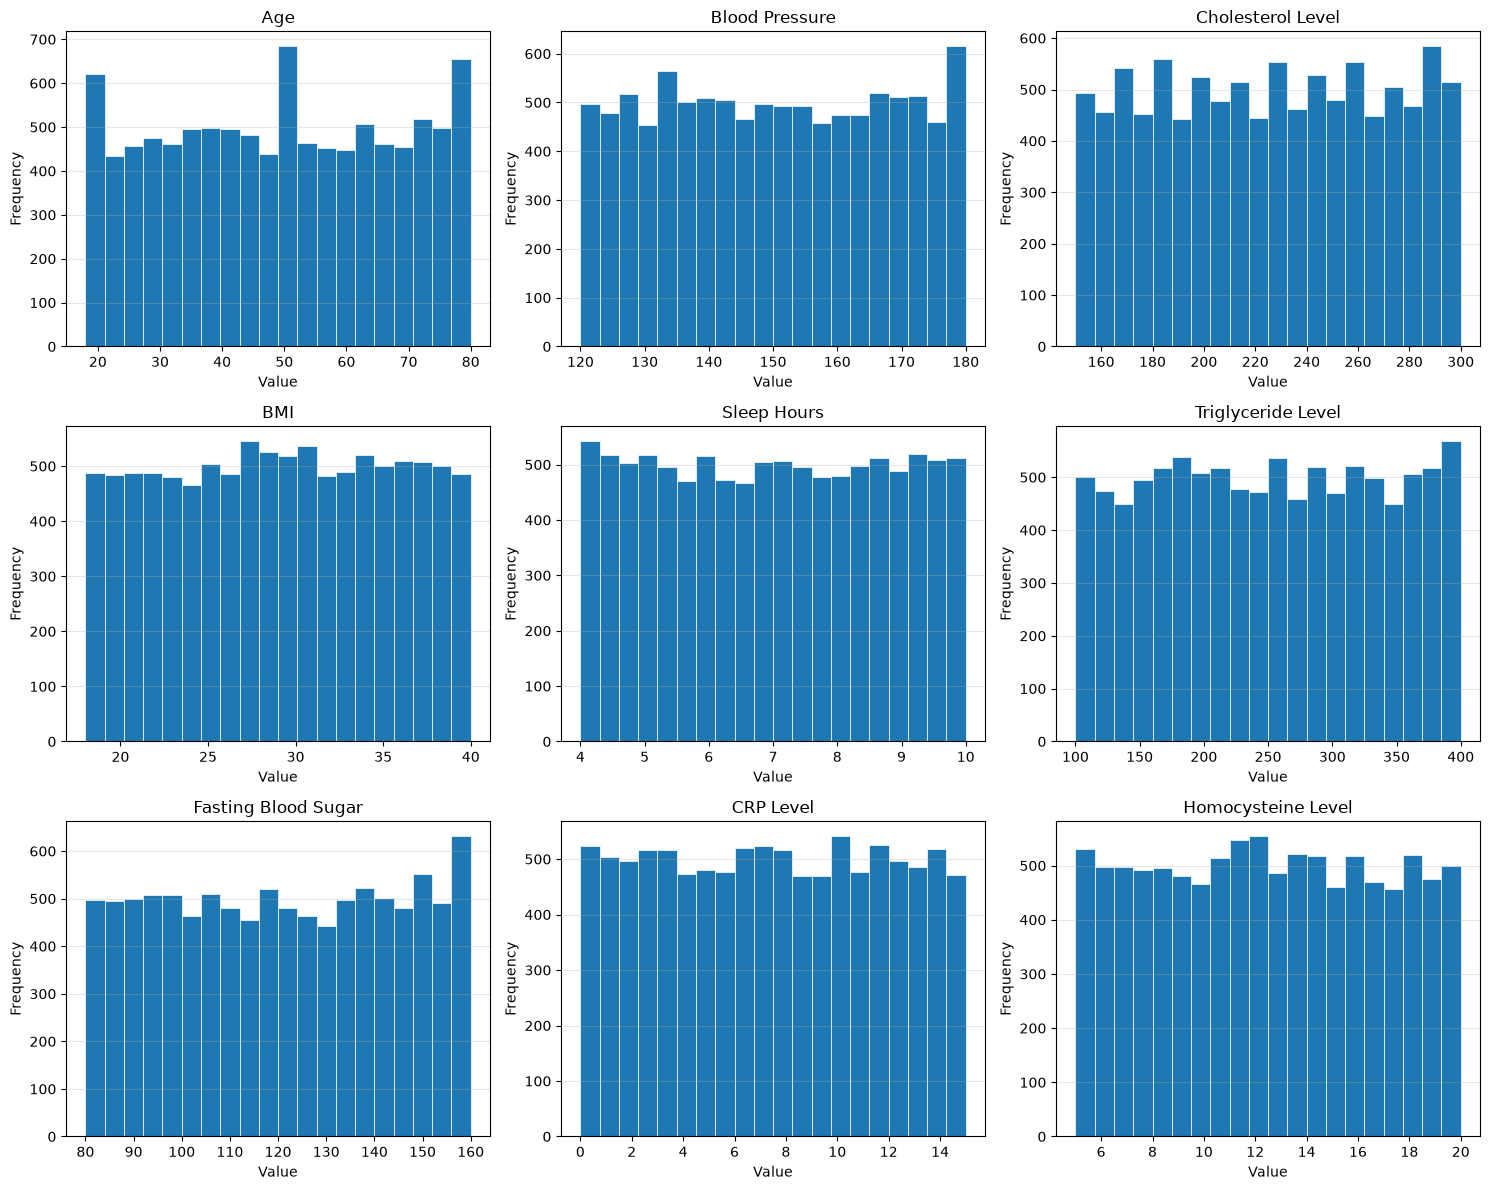

In [17]:

import matplotlib.pyplot as plt
import numpy as np
import math

# Select numerical columns
scaled = data.select_dtypes(include=np.number).dropna()

# Number of columns and rows
n_cols = 3
n_rows = math.ceil(len(scaled.columns) / n_cols)

# Create subplots
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, n_rows * 4)
)

axes = axes.flatten()

# Plot each column
for i, column in enumerate(scaled.columns):
    axes[i].hist(
        scaled[column],
        bins=20,
        linewidth=0.5,
        edgecolor="white"
    )

    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.3)

# Remove unused subplots
for i in range(len(scaled.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()


Escalar columnas numéricas

In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))

scaled = scaler.fit_transform(scaled)

scaled

array([[0.61290323, 0.55      , 0.03333333, ..., 0.50177766, 0.86475145,
        0.49250698],
       [0.82258065, 0.43333333, 0.90666667, ..., 0.9625    , 0.62372229,
        0.95331883],
       [0.4516129 , 0.1       , 0.44      , ..., 0.15      , 0.84745234,
        0.4154125 ],
       ...,
       [0.88709677, 0.53333333, 0.34      , ..., 0.1       , 0.29380985,
        0.29950345],
       [0.08064516, 0.36666667, 0.99333333, ..., 0.9125    , 0.48100951,
        0.45825327],
       [0.32258065, 0.13333333, 0.28666667, ..., 0.8625    , 0.95936377,
        0.08055942]], shape=(10000, 9))

In [19]:
data[ 
    [
    'Age', 
    'Blood Pressure', 
    'Cholesterol Level', 
    'BMI', 'Sleep Hours', 
    'Triglyceride Level', 
    'Fasting Blood Sugar', 
    'CRP Level',
    'Homocysteine Level'
    ]
] = scaled
data

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,0.612903,1,0.550000,0.033333,2,1,1,0,0.317756,1,...,0,2,1,0.605503,1,0.806667,0.501778,0.864751,0.492507,0
1,0.822581,0,0.433333,0.906667,2,0,1,1,0.328222,0,...,0,1,2,0.790657,1,0.110000,0.962500,0.623722,0.953319,0
2,0.451613,1,0.100000,0.440000,0,0,0,0,0.538899,0,...,1,0,0,0.073314,0,0.976667,0.150000,0.847452,0.415412,0
3,0.225806,0,0.033333,0.953333,2,1,1,0,0.278604,1,...,1,0,2,0.208156,2,0.643333,0.175000,0.834058,0.064120,0
4,0.677419,1,0.766667,0.613333,0,1,1,1,0.112914,1,...,0,0,2,0.505116,2,0.543333,0.925000,0.692144,0.210260,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0.112903,0,0.266667,0.620000,1,1,0,0,0.035735,1,...,1,1,2,0.472443,1,0.810000,0.662500,0.239116,0.942193,1
9996,0.322581,1,0.866667,0.026667,1,0,0,0,0.629894,1,...,1,1.0,2,0.707940,0,0.923333,0.037500,0.177052,0.314390,1
9997,0.887097,1,0.533333,0.340000,2,1,0,1,0.404521,0,...,1,1.0,0,0.072701,0,0.493333,0.100000,0.293810,0.299503,1
9998,0.080645,1,0.366667,0.993333,0,1,0,1,0.771169,1,...,1,1,2,0.754369,1,0.043333,0.912500,0.481010,0.458253,1


## Tensor Loader

Cast every column to float64

In [28]:
data = data.apply(lambda col: pd.to_numeric(col, errors="coerce")).astype("float64")

print(data.dtypes)

Age                     float64
Gender                  float64
Blood Pressure          float64
Cholesterol Level       float64
Exercise Habits         float64
Smoking                 float64
Family Heart Disease    float64
Diabetes                float64
BMI                     float64
High Blood Pressure     float64
Low HDL Cholesterol     float64
High LDL Cholesterol    float64
Alcohol Consumption     float64
Stress Level            float64
Sleep Hours             float64
Sugar Consumption       float64
Triglyceride Level      float64
Fasting Blood Sugar     float64
CRP Level               float64
Homocysteine Level      float64
Heart Disease Status    float64
dtype: object


Split Data

In [29]:
from sklearn.model_selection import train_test_split

X = data.drop(columns='Heart Disease Status')
y = data['Heart Disease Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

Load into TensorDatasets and then DataLoaders

In [30]:
from torch.utils.data import TensorDataset, DataLoader
import torch

X_train = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
X_test = torch.tensor(X_test.to_numpy(), dtype=torch.float32)

y_train = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

In [31]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)

## CUDA

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando en: {device}")

Entrenando en: cuda


## ANN Arquitecture

Entry Layer Nodes Amount

In [25]:
len(data.columns)

21

Arquitecture: 21 (inputs) -> 64 -> 64 -> 32 -> 2 (outputs)

Activation Function: ReLU

Optimizer: BCE With Logits Loss

Loss Function: Adam W

In [26]:
import torch.nn as nn

def initANN():

    class HeartDiseasePredictor(nn.Module):

        def __init__(self):
            super().__init__()
            
            self.input = nn.Linear(21, 64)

            self.fc1 = nn.Linear(64,64)
            self.fc2 = nn.Linear(64,32)

            self.output = nn.Linear(32,2)

            self.relu = F.relu()

        def forward(self, X):
            # X = X.view(X.shape[0], -1)
            
            X = self.relu( self.input(X) )
            X = self.relu( self.fc1(X) )
            X = self.relu( self.fc2(X) )
            X = self.output(X) 

    # Model
    net = HeartDiseasePredictor()

    # Optimizer

    # Loss Function